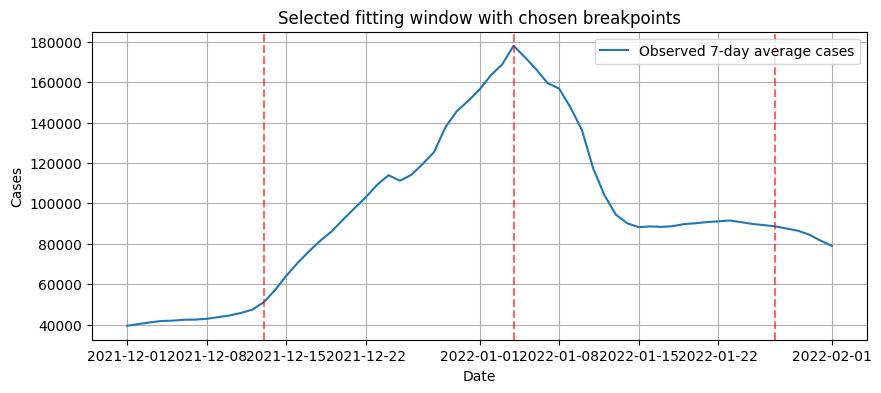

Break dates: ['2021-12-13', '2022-01-04', '2022-01-27']
Break indices: [12, 34, 57]


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

data = df_fit["cases_7d"].values
t = np.arange(len(data))

# population
N = 67_000_000

# initial values
I0 = float(data[0])
R0 = 0.0
S0 = N - I0 - R0

# chosen breakpoints
break_dates = ["2021-12-13", "2022-01-04", "2022-01-27"]
break_indices = [int(np.where(df_fit["date"] == pd.Timestamp(d))[0][0]) for d in break_dates]

plt.figure(figsize=(10, 4))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.6)
plt.title("Selected fitting window with chosen breakpoints")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

print("Break dates:", break_dates)
print("Break indices:", break_indices)

In [9]:
def beta_piecewise_exp(tt, break_indices, beta_base, lambdas):
    bounds = [0] + break_indices + [10**9]
    for k in range(len(beta_base)):
        if bounds[k] <= tt < bounds[k + 1]:
            local_t = tt - bounds[k]
            return beta_base[k] * np.exp(-lambdas[k] * local_t)
    return beta_base[-1]

def sir_model_piecewise_exp(t_now, y, break_indices, beta_base, lambdas, gamma, N):
    S, I, R = y
    beta_t = beta_piecewise_exp(t_now, break_indices, beta_base, lambdas)

    dSdt = -beta_t * S * I / N
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

def simulate_piecewise_exp(break_indices, beta_base, lambdas, gamma, S0, I0, R0, N, t_eval):
    sol = solve_ivp(
        fun=lambda t_now, y: sir_model_piecewise_exp(t_now, y, break_indices, beta_base, lambdas, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=[S0, I0, R0],
        t_eval=t_eval,
        method="RK45"
    )

    S = sol.y[0]
    I = sol.y[1]
    R = sol.y[2]
    beta_path = np.array([beta_piecewise_exp(tt, break_indices, beta_base, lambdas) for tt in t_eval])

    return S, I, R, beta_path

n_seg = len(break_indices) + 1

def loss_fn(params):
    beta_base = params[:n_seg]
    lambdas = params[n_seg:2*n_seg]
    gamma = params[-1]

    if np.any(np.array(beta_base) <= 0) or np.any(np.array(lambdas) < 0) or gamma <= 0:
        return 1e20

    S_fit, I_fit, R_fit, beta_path = simulate_piecewise_exp(
        break_indices, beta_base, lambdas, gamma, S0, I0, R0, N, t
    )

    if len(I_fit) != len(data) or np.any(np.isnan(I_fit)) or np.any(np.isinf(I_fit)):
        return 1e20

    return np.mean((I_fit - data) ** 2)

# initial guess
x0 = [0.08] * n_seg + [0.01] * n_seg + [0.05]

# bounds: beta_base, lambdas, gamma
bounds = [(1e-6, 1.0)] * n_seg + [(0.0, 0.2)] * n_seg + [(1e-6, 1.0)]

result = minimize(
    loss_fn,
    x0=x0,
    bounds=bounds,
    method="L-BFGS-B"
)

best_params = result.x
beta_base = best_params[:n_seg]
lambdas = best_params[n_seg:2*n_seg]
gamma = best_params[-1]

S_fit, I_fit, R_fit, beta_path = simulate_piecewise_exp(
    break_indices, beta_base, lambdas, gamma, S0, I0, R0, N, t
)

mse = np.mean((I_fit - data) ** 2)
rmse = np.sqrt(mse)

print("Chosen model: policy_natural_1213_0104_0127")
print("Break dates:", break_dates)
print("beta_base =", beta_base)
print("lambdas   =", lambdas)
print("gamma     =", gamma)
print("MSE       =", mse)
print("RMSE      =", rmse)

Chosen model: policy_natural_1213_0104_0127
Break dates: ['2021-12-13', '2022-01-04', '2022-01-27']
beta_base = [0.1244809  0.11323162 0.04704281 0.11782041]
lambdas   = [0.00718181 0.         0.04232317 0.00869153]
gamma     = 0.07192962397946198
MSE       = 148844218.73339805
RMSE      = 12200.172897684608


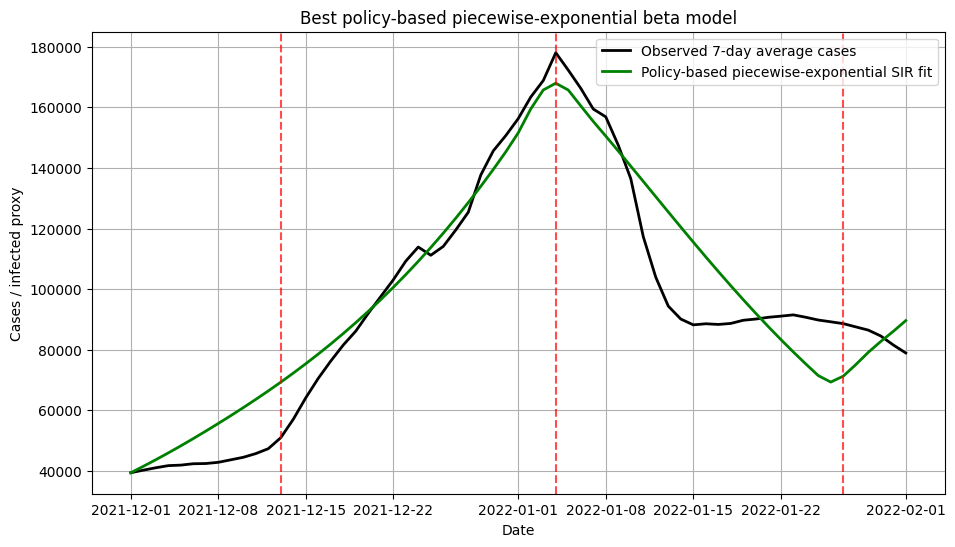

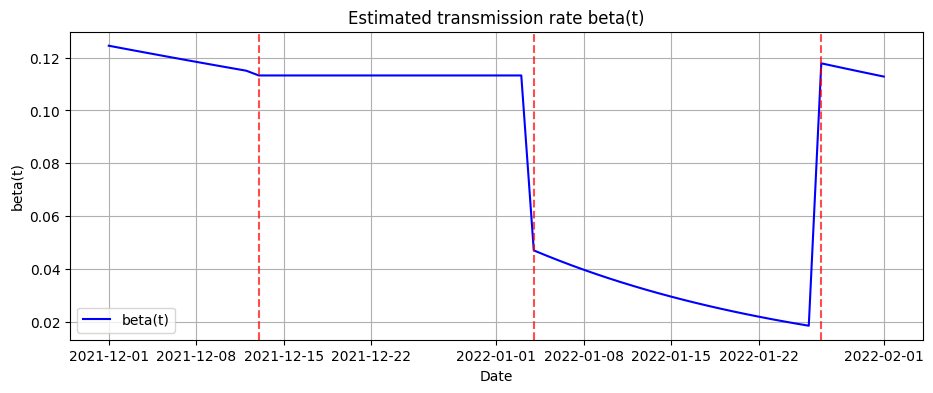

        quantity             value
0   breakpoint_1        2021-12-13
1   breakpoint_2        2022-01-04
2   breakpoint_3        2022-01-27
3          beta1          0.124481
4          beta2          0.113232
5          beta3          0.047043
6          beta4           0.11782
7        lambda1          0.007182
8        lambda2               0.0
9        lambda3          0.042323
10       lambda4          0.008692
11         gamma           0.07193
12           MSE  148844218.733398
13          RMSE      12200.172898


In [10]:
# fitted curve
plt.figure(figsize=(11, 6))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases", linewidth=2, color="black")
plt.plot(df_fit["date"], I_fit, label="Policy-based piecewise-exponential SIR fit", linewidth=2, color="green")

for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)

plt.title("Best policy-based piecewise-exponential beta model")
plt.xlabel("Date")
plt.ylabel("Cases / infected proxy")
plt.legend()
plt.grid()
plt.show()

# beta(t)
plt.figure(figsize=(11, 4))
plt.plot(df_fit["date"], beta_path, label="beta(t)", color="blue")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
plt.title("Estimated transmission rate beta(t)")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.show()

# summary table
summary = pd.DataFrame({
    "quantity": [
        "breakpoint_1", "breakpoint_2", "breakpoint_3",
        "beta1", "beta2", "beta3", "beta4",
        "lambda1", "lambda2", "lambda3", "lambda4",
        "gamma", "MSE", "RMSE"
    ],
    "value": [
        break_dates[0], break_dates[1], break_dates[2],
        beta_base[0], beta_base[1], beta_base[2], beta_base[3],
        lambdas[0], lambdas[1], lambdas[2], lambdas[3],
        gamma, mse, rmse
    ]
})

print(summary)